In [1]:
import train_add
import numpy as np
import matplotlib.pyplot as plt

We train 20 different neural networks with different seeds.

In [2]:
toys = []
for i in range(20):
    toy = train_add.train_add(seed = i)
    toys.append(toy)

Using device: cpu
----------------------------------------
Task 1: Analyzing the dataset before training...
acc_ideal_test = 5/10=0.5
the degree of freedom (except translation/scaling) for the reprsentation is 0
dof=0 means the linear repr is the unique repr, while dof>0 means existence of other reprs
----------------------------------------
Task 2: Training with neural network...
step: 0  | loss: 0.96702546 
step: 1000  | loss: 0.41594812 
step: 2000  | loss: 0.09189018 
step: 3000  | loss: 0.01310764 
step: 4000  | loss: 0.00050267 
final train acc=1.0000, test acc=0.5000, RQI=1.0000
Steps to reach thresholds: train acc=1157, test acc=4999, RQI=833
----------------------------------------
Task 3: Training with effective loss...
step: 0  | loss: 312.88660324 
step: 1000  | loss: 0.00026023 
step: 2000  | loss: 0.00000000 
step: 3000  | loss: 0.00000000 
step: 4000  | loss: 0.00000000 
saving trajectories...
Using device: cpu
----------------------------------------
Task 1: Analyzing t

We extract information that useful to understanding their behavior

In [3]:
rqis = []

toy = toys[0]
steps = toy["steps"]
p = toy["p"]
converge = []
for i in range(20):
    toy = toys[i]
    repr_norm = np.squeeze(toy["repr_normalized_nn"])
    repr_eff = toy["repr_eff"]
    rqis.append(toy["rqi"])
    converge.append(np.sum(abs(repr_norm[steps-1]-repr_eff[steps-1]))/p)# average difference between the two representations

In [4]:
max_toy_idx = np.argmax(converge)

In [5]:
min_toy_idx = np.argmin(converge)

In [6]:
np.sum(list(map(lambda x: x[steps-1]>(0.95) ,rqis)))/len(rqis)# percentage that finds a linear representation

np.float64(0.65)

In [7]:
np.sum(list(map(lambda x: x<(0.01) ,converge)))/len(converge)# percentage that converges

np.float64(0.55)

plot of the best and worst fitting prediction.

In [8]:
max_toy = toys[max_toy_idx]
max_repr_norm = np.squeeze(max_toy["repr_normalized_nn"]) # squeeze changes shape from 5000,10,1 to 5000,10 this makes it consistent with repr_eff
max_repr_eff = max_toy["repr_eff"]

min_toy = toys[min_toy_idx]
min_repr_norm = np.squeeze(min_toy["repr_normalized_nn"]) # squeeze changes shape from 5000,10,1 to 5000,10 this makes it consistent with repr_eff
min_repr_eff = min_toy["repr_eff"]

Text(0.5, 1.0, 'Empirical: trajectory')

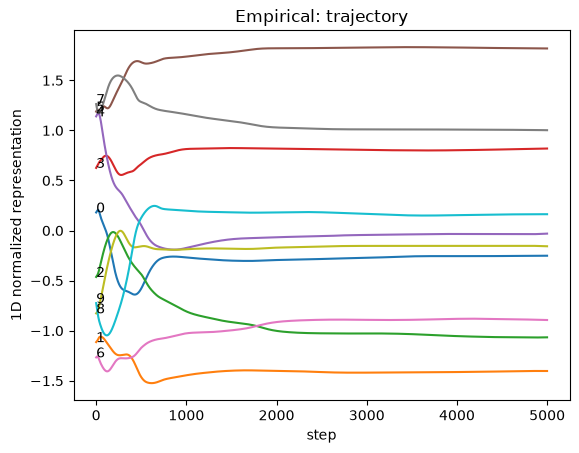

In [9]:
for i in range(p):
    plt.plot(np.arange(steps), max_repr_norm[:,i])
    plt.text(0, max_repr_norm[0,i], i)
plt.xlabel("step")
plt.ylabel("1D normalized representation")
plt.title("Empirical: trajectory")

Text(0.5, 1.0, 'Theory: trajectory')

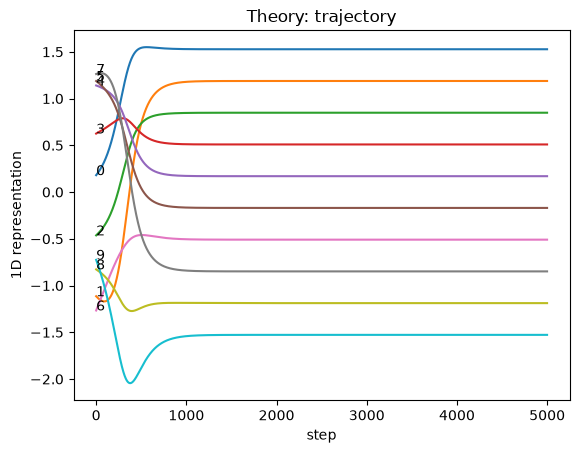

In [10]:
for i in range(p):
    plt.plot(np.arange(steps), max_repr_eff[:,i])
    plt.text(0, max_repr_eff[0,i], i)
plt.xlabel("step")
plt.ylabel("1D representation")
plt.title("Theory: trajectory")

Text(0.5, 1.0, 'Empirical: trajectory')

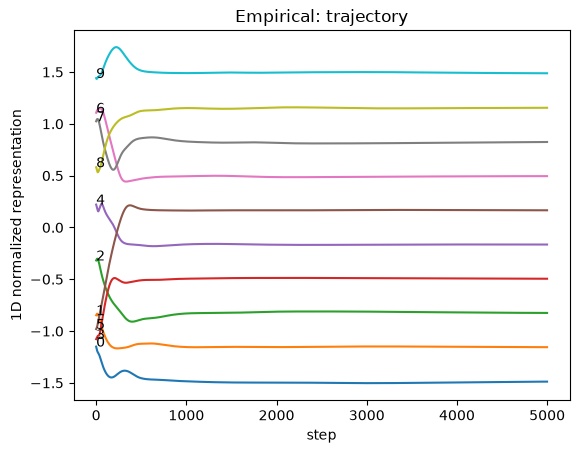

In [11]:
for i in range(p):
    plt.plot(np.arange(steps), min_repr_norm[:,i])
    plt.text(0, min_repr_norm[0,i], i)
plt.xlabel("step")
plt.ylabel("1D normalized representation")
plt.title("Empirical: trajectory")

Text(0.5, 1.0, 'Theory: trajectory')

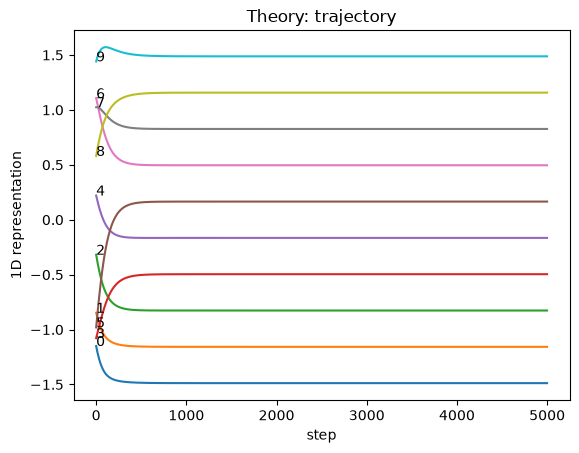

In [12]:
for i in range(p):
    plt.plot(np.arange(steps), min_repr_eff[:,i])
    plt.text(0, min_repr_eff[0,i], i)
plt.xlabel("step")
plt.ylabel("1D representation")
plt.title("Theory: trajectory")

Comparing convergence of networks that found a linear representation vs those that didn't

In [13]:
diff = []
for i in range(20):
    toy = toys[i]
    repr_norm = np.squeeze(toy["repr_normalized_nn"]) 
    repr_eff = toy["repr_eff"]
    if list(map(lambda x: x[steps-1]>(0.95) ,rqis))[i]:
        diff.append(np.average(abs(repr_norm-repr_eff), axis=1))

Text(0.5, 1.0, 'Convergence: linear representation')

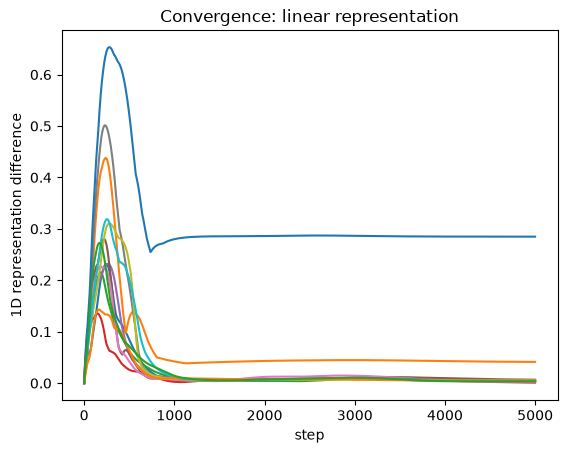

In [14]:
for i in range(len(diff)):
    plt.plot(diff[i])
plt.xlabel("step")
plt.ylabel("1D representation difference")
plt.title("Convergence: linear representation")

In [15]:
diff = []
for i in range(20):
    toy = toys[i]
    repr_norm = np.squeeze(toy["repr_normalized_nn"]) 
    repr_eff = toy["repr_eff"]
    if not list(map(lambda x: x[steps-1]>(0.95) ,rqis))[i]:
        diff.append(np.average(abs(repr_norm-repr_eff), axis=1))

Text(0.5, 1.0, 'Convergence: non-linear representation')

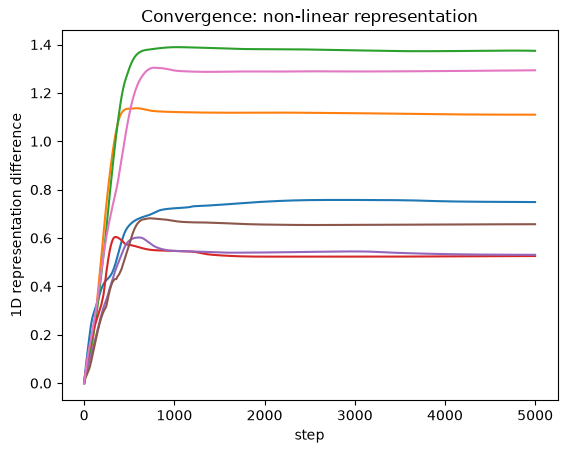

In [16]:
for i in range(len(diff)):
    plt.plot(diff[i])
plt.xlabel("step")
plt.ylabel("1D representation difference")
plt.title("Convergence: non-linear representation")